In [53]:
import json
import os
import subprocess

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [54]:
root_path = "../"

trizod_filename = os.path.join(root_path, "datasets/cleaned_trizod_dataset.csv")
trizod_df = pd.read_csv(
    trizod_filename,
    index_col="label",
    converters={"gscores": lambda x: np.array(json.loads(x), dtype=float)},
)
# df_train = trizod_df[~trizod_df["is_test"]]
df_test = trizod_df[trizod_df["is_test"]]

In [55]:
filename = "test.csv"

if not os.path.exists(filename):
    fasta_filename = "test.fasta"
    with open(fasta_filename, "w") as f:
        for label, row in df_test.iterrows():
            f.write(f">{label}\n{row['sequence']}\n")

    subprocess.run(
        [
            "adopt2g-predict",
            "--input",
            fasta_filename,
            "--out",
            filename,
            "--save-member-gscores",
            # "--ensemble-id",
            # "seed883_n5",
        ],
        check=True,
    )
    os.remove(fasta_filename)
df_inferred = pd.read_csv(
    filename,
    index_col="label",
    converters={
        "gscores": lambda x: np.array(json.loads(x), dtype=float),
        "gscores_lower": lambda x: np.array(json.loads(x), dtype=float),
        "gscores_upper": lambda x: np.array(json.loads(x), dtype=float),
        "member_gscores": lambda x: np.array(json.loads(x), dtype=float),
    },
)
df_inferred

,sequence,mean_gscore,mean_gscore_lower,mean_gscore_upper,gscores,gscores_lower,gscores_upper,member_gscores
label,,,,,,,,
1474_1_1_1,DYAKCVFPFIYGGKKYETCTKIGSMWMSWCSLSPNYDKDRAWKYC,0.111600,0.086752,0.142456,"[0.3099628535041738, 0.25515801743284344, 0.26...","[0.14584377135587895, 0.13072868194347034, 0.1...","[0.5415300741064153, 0.4381840798637683, 0.381...","[[0.2989005026108704, 0.2653090254809762, 0.26..."
1710_1_1_1,KWKLFKKIEKVGQGIGAVLKVLTTG,0.200312,0.073537,0.441491,"[0.25534365985620666, 0.24725966834322632, 0.2...","[0.12095702846131734, 0.10158944591881584, 0.0...","[0.46077413201779915, 0.48803939154346987, 0.4...","[[0.2797301023993239, 0.24220562872535947, 0.2..."
4112_1_1_1,MAKEFGIPAAVAGTVLNVVEAGGWVTTIVSILTAVGSGGLSLLAAA...,0.187898,0.080466,0.379559,"[0.2895725548399111, 0.2178362791958119, 0.257...","[0.15115305795512232, 0.05602938511788175, 0.1...","[0.48267295667550336, 0.5664982418472789, 0.50...","[[0.2869678647289528, 0.23917159840433075, 0.2..."
4230_1_1_1,MNTPEHMTAVVQRYVAALNAGDLDGIVALFADDATVEDPVGSEPRS...,0.070158,0.021328,0.207125,"[0.2756168888835264, 0.19178137244926485, 0.18...","[0.07558479067867369, 0.06853749303199023, 0.0...","[0.6389479307034645, 0.433501758152721, 0.4220...","[[0.2887696209741698, 0.1887722142202807, 0.19..."
4273_1_1_1,RERDHELRHRRHHHQ,0.413219,0.111655,0.797800,"[0.4038607123243845, 0.3739901328813332, 0.442...","[0.0870968264035303, 0.14681969604457246, 0.12...","[0.8279672966770677, 0.6745866486160489, 0.810...","[[0.4194101348071259, 0.3564466586700417, 0.45..."
...,...,...,...,...,...,...,...,...
52388_1_1_1,ETVSPLPSSMDLLIQDSPDSSTSPKG,0.715878,0.235216,0.953793,"[0.5441353195759139, 0.694924132784345, 0.6766...","[0.06853749303199023, 0.1770981534389491, 0.18...","[0.9509603749892346, 0.9602121916306376, 0.949...","[[0.6649755758815485, 0.7568970420586438, 0.74..."
52410_1_1_1,TPFMTCFAPRVDCRKSSSAL,0.479634,0.005292,0.993777,"[0.39227862646244965, 0.4009252626266813, 0.48...","[0.014337030424010801, 0.004867417345279047, 0...","[0.9662197710315901, 0.9891815513471369, 0.995...","[[0.34125312686469006, 0.3021851158828259, 0.3..."
52420_1_1_1,GSANYSQVAHIPKSDALYFDDCMQLLAQTFPFVDDNEVSSATFQSL...,0.687282,0.015812,0.996685,"[0.7826624789529376, 0.8390757441161931, 0.816...","[0.02976009394596422, 0.06903792817478999, 0.0...","[0.9976403393179369, 0.9972850145309949, 0.997...","[[0.8840392817460332, 0.8992983918150725, 0.87..."


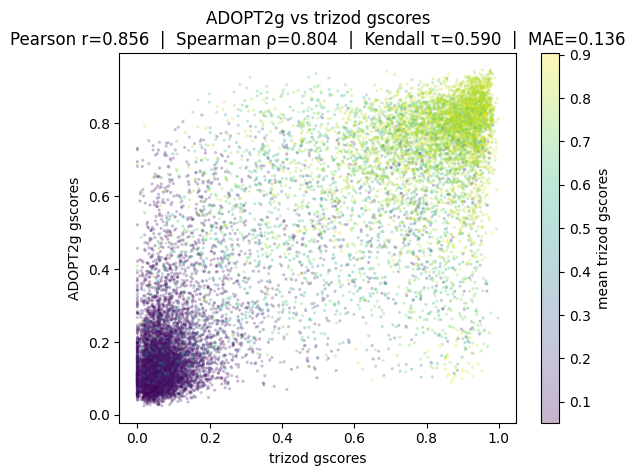

Summary of metrics for each member and mean prediction:

member_id  pearson_r  spearman_rho  kendall_tau    mae
     mean     0.8559        0.8038       0.5897 0.1357
        0     0.8515        0.7990       0.5844 0.1364
        1     0.8536        0.8004       0.5862 0.1370
        2     0.8476        0.7965       0.5806 0.1391
        3     0.8540        0.8018       0.5876 0.1360
        4     0.8537        0.8010       0.5861 0.1377
        5     0.8526        0.8017       0.5869 0.1371
        6     0.8506        0.8005       0.5860 0.1369
No members have better metrics than the mean prediction.


In [56]:
from scipy.stats import kendalltau, pearsonr, spearmanr

member_metrics = []
mean_trizod_gscores = np.repeat(df_test["gscores"].apply(np.nanmean).values, df_test["gscores"].apply(len).values)
trizod_gscores = np.concatenate(df_test["gscores"].values)
adopt2_gscores = np.concatenate(df_inferred["gscores"].values)
mask = np.isfinite(trizod_gscores) & np.isfinite(adopt2_gscores)

# Compute correlation metrics
pearson_r, _ = pearsonr(trizod_gscores[mask], adopt2_gscores[mask])
spearman_rho, _ = spearmanr(trizod_gscores[mask], adopt2_gscores[mask])
kendall_tau, _ = kendalltau(trizod_gscores[mask], adopt2_gscores[mask])

# Also compute MAE for prediction accuracy
mae = np.mean(np.abs(trizod_gscores[mask] - adopt2_gscores[mask]))

member_metrics.append(
    {
        "member_id": "mean",
        "pearson_r": pearson_r,
        "spearman_rho": spearman_rho,
        "kendall_tau": kendall_tau,
        "mae": mae,
    },
)

plt.scatter(trizod_gscores, adopt2_gscores, alpha=0.3, s=5, lw=0, c=mean_trizod_gscores)
plt.xlabel("trizod gscores")
plt.ylabel("ADOPT2g gscores")
plt.title(
    f"ADOPT2g vs trizod gscores\nPearson r={pearson_r:.3f}  |  Spearman ρ={spearman_rho:.3f}  |  Kendall τ={kendall_tau:.3f}  |  MAE={mae:.3f}",
)
plt.colorbar(label="mean trizod gscores")
plt.show()

n_members = len(df_inferred["member_gscores"].iloc[0]) if "member_gscores" in df_inferred.columns else 0

# Prepare to collect summary stats for each member
for m in range(n_members):
    mean_trizod_gscores = np.repeat(df_test["gscores"].apply(np.nanmean).values, df_test["gscores"].apply(len).values)
    trizod_gscores = np.concatenate(df_test["gscores"].values)
    # Select the gscores for the current member 'm' from the 2D list in each row, then flatten
    adopt2_gscores = np.concatenate([gscores[m] for gscores in df_inferred["member_gscores"].values])
    mask = np.isfinite(trizod_gscores) & np.isfinite(adopt2_gscores)

    # Compute correlation metrics
    pearson_r, _ = pearsonr(trizod_gscores[mask], adopt2_gscores[mask])
    spearman_rho, _ = spearmanr(trizod_gscores[mask], adopt2_gscores[mask])
    kendall_tau, _ = kendalltau(trizod_gscores[mask], adopt2_gscores[mask])

    # Also compute MAE for prediction accuracy
    mae = np.mean(np.abs(trizod_gscores[mask] - adopt2_gscores[mask]))

    member_metrics.append(
        {
            "member_id": m,
            "pearson_r": pearson_r,
            "spearman_rho": spearman_rho,
            "kendall_tau": kendall_tau,
            "mae": mae,
        },
    )

    # plt.scatter(trizod_gscores, adopt2_gscores, alpha=0.3, s=5, lw=0, c=mean_trizod_gscores)
    # plt.xlabel("trizod gscores")
    # plt.ylabel("ADOPT2g gscores")
    # plt.title(
    #     f"m={m}: ADOPT2g vs trizod gscores\nPearson r={pearson_r:.3f}  |  Spearman ρ={spearman_rho:.3f}  |  Kendall τ={kendall_tau:.3f}  |  MAE={mae:.3f}",
    # )
    # plt.colorbar(label="mean trizod gscores")
    # plt.show()

if n_members > 0:
    summary_df = pd.DataFrame(member_metrics)
    print("Summary of metrics for each member and mean prediction:\n")
    print(summary_df.to_string(index=False, float_format="%.4f"))

    # Check if any member has better metric than mean
    # Lower MAE is better, higher correlation is better
    mae_mean = summary_df["mae"][summary_df["member_id"] == "mean"].values[0]
    pearson_r_mean = summary_df["pearson_r"][summary_df["member_id"] == "mean"].values[0]
    spearman_rho_mean = summary_df["spearman_rho"][summary_df["member_id"] == "mean"].values[0]
    kendall_tau_mean = summary_df["kendall_tau"][summary_df["member_id"] == "mean"].values[0]

    better_mae_members = summary_df[summary_df["mae"] < mae_mean]["member_id"].tolist()
    better_pearson_members = summary_df[summary_df["pearson_r"] > pearson_r_mean]["member_id"].tolist()
    better_spearman_members = summary_df[summary_df["spearman_rho"] > spearman_rho_mean]["member_id"].tolist()
    better_kendall_members = summary_df[summary_df["kendall_tau"] > kendall_tau_mean]["member_id"].tolist()

    if better_mae_members or better_pearson_members or better_spearman_members or better_kendall_members:
        print("\nWARNING: Some members have better metrics than the mean prediction:")
        if better_mae_members:
            print(f"  Members with lower MAE than mean: {better_mae_members}")
        if better_pearson_members:
            print(f"  Members with higher Pearson r than mean: {better_pearson_members}")
        if better_spearman_members:
            print(f"  Members with higher Spearman rho than mean: {better_spearman_members}")
        if better_kendall_members:
            print(f"  Members with higher Kendall tau than mean: {better_kendall_members}")
    else:
        print("No members have better metrics than the mean prediction.")


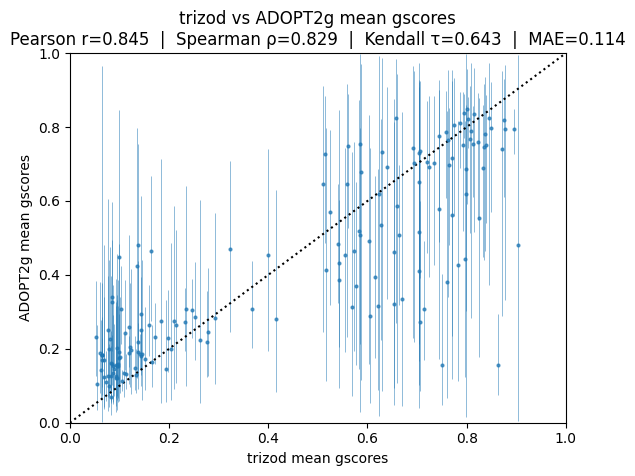

In [57]:
# Compute correlation metrics for mean gscores
pearson_r_mean, _ = pearsonr(df_test["mean_gscore"], df_inferred["mean_gscore"])
spearman_rho_mean, _ = spearmanr(df_test["mean_gscore"], df_inferred["mean_gscore"])
kendall_tau_mean, _ = kendalltau(df_test["mean_gscore"], df_inferred["mean_gscore"])
mae_mean = np.mean(np.abs(df_test["mean_gscore"].values - df_inferred["mean_gscore"].values))

plt.errorbar(
    df_test["mean_gscore"],
    df_inferred["mean_gscore"],
    yerr=[
        df_inferred["mean_gscore"] - df_inferred["mean_gscore_lower"],
        df_inferred["mean_gscore_upper"] - df_inferred["mean_gscore"],
    ],
    fmt="o",
    markersize=2,
    elinewidth=0.5,
    alpha=0.7,
    capsize=0,
)
plt.xlabel("trizod mean gscores")
plt.ylabel("ADOPT2g mean gscores")
plt.title(
    f"trizod vs ADOPT2g mean gscores\nPearson r={pearson_r_mean:.3f}  |  Spearman ρ={spearman_rho_mean:.3f}  |  Kendall τ={kendall_tau_mean:.3f}  |  MAE={mae_mean:.3f}",
)
plt.axline((0.5, 0.5), slope=1, color="k", ls=":")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.show()


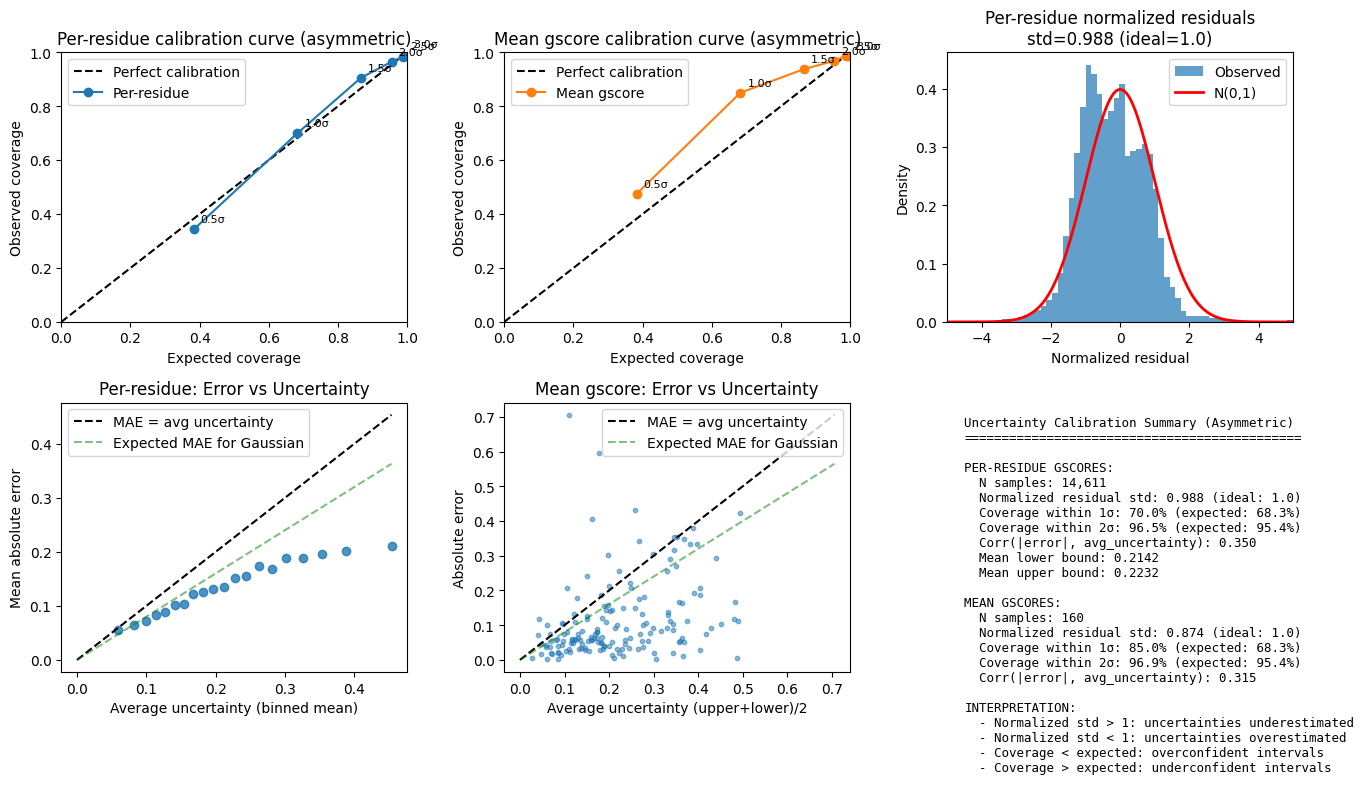

In [58]:
# Uncertainty calibration analysis with asymmetric intervals
# For well-calibrated uncertainties, ~68% of true values should fall within the 1σ interval, ~95% within 2σ

# --- Per-residue uncertainty calibration (asymmetric) ---
trizod_gscores = np.concatenate(df_test["gscores"].values)
pred_gscores = np.concatenate(df_inferred["gscores"].values)
pred_gscores_lower = np.concatenate(df_inferred["gscores_lower"].values)
pred_gscores_upper = np.concatenate(df_inferred["gscores_upper"].values)

# Compute asymmetric uncertainties (distance from prediction to bounds)
pred_err_lower = pred_gscores - pred_gscores_lower  # positive: how far below pred the lower bound is
pred_err_upper = pred_gscores_upper - pred_gscores  # positive: how far above pred the upper bound is

# Mask for valid values
mask = (
    np.isfinite(trizod_gscores)
    & np.isfinite(pred_gscores)
    & np.isfinite(pred_gscores_lower)
    & np.isfinite(pred_gscores_upper)
    & (pred_err_lower > 0)
    & (pred_err_upper > 0)
)
true_vals = trizod_gscores[mask]
pred_vals = pred_gscores[mask]
err_lower = pred_err_lower[mask]
err_upper = pred_err_upper[mask]

# Compute z-scores using asymmetric bounds
# Use upper bound for positive residuals (true > pred), lower bound for negative residuals
residuals = true_vals - pred_vals
z_scores = np.where(
    residuals >= 0,
    residuals / err_upper,  # true above pred: normalize by upper uncertainty
    residuals / err_lower,  # true below pred: normalize by lower uncertainty (gives negative z)
)

# For binned analysis, use average uncertainty width
avg_err = (err_lower + err_upper) / 2

# Calibration: fraction of points within n-scaled intervals
n_sigmas = np.array([0.5, 1, 1.5, 2, 2.5, 3])
from scipy.stats import norm

expected_coverage = np.array([norm.cdf(n) - norm.cdf(-n) for n in n_sigmas])

# For asymmetric intervals: check if true is within [pred - n*err_lower, pred + n*err_upper]
observed_coverage_residue = np.array(
    [np.mean((true_vals >= pred_vals - n * err_lower) & (true_vals <= pred_vals + n * err_upper)) for n in n_sigmas],
)

# --- Mean gscore uncertainty calibration (asymmetric) ---
true_mean = df_test["mean_gscore"].values
pred_mean = df_inferred["mean_gscore"].values
pred_mean_lower = df_inferred["mean_gscore_lower"].values
pred_mean_upper = df_inferred["mean_gscore_upper"].values

# Asymmetric uncertainties for mean
mean_err_lower = pred_mean - pred_mean_lower
mean_err_upper = pred_mean_upper - pred_mean

mask_mean = (
    np.isfinite(true_mean)
    & np.isfinite(pred_mean)
    & np.isfinite(pred_mean_lower)
    & np.isfinite(pred_mean_upper)
    & (mean_err_lower > 0)
    & (mean_err_upper > 0)
)
residuals_mean = true_mean[mask_mean] - pred_mean[mask_mean]
z_scores_mean = np.where(
    residuals_mean >= 0,
    residuals_mean / mean_err_upper[mask_mean],
    residuals_mean / mean_err_lower[mask_mean],
)

observed_coverage_mean = np.array(
    [
        np.mean(
            (true_mean[mask_mean] >= pred_mean[mask_mean] - n * mean_err_lower[mask_mean])
            & (true_mean[mask_mean] <= pred_mean[mask_mean] + n * mean_err_upper[mask_mean]),
        )
        for n in n_sigmas
    ],
)

# --- Plotting ---
fig, axes = plt.subplots(2, 3, figsize=(14, 8))

# 1. Calibration curve - Per-residue
ax = axes[0, 0]
ax.plot([0, 1], [0, 1], "k--", label="Perfect calibration")
ax.plot(expected_coverage, observed_coverage_residue, "o-", color="tab:blue", label="Per-residue")
ax.set_xlabel("Expected coverage")
ax.set_ylabel("Observed coverage")
ax.set_title("Per-residue calibration curve (asymmetric)")
ax.legend()
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
for i, n in enumerate(n_sigmas):
    ax.annotate(
        f"{n}σ",
        (expected_coverage[i], observed_coverage_residue[i]),
        textcoords="offset points",
        xytext=(5, 5),
        fontsize=8,
    )

# 2. Calibration curve - Mean gscore
ax = axes[0, 1]
ax.plot([0, 1], [0, 1], "k--", label="Perfect calibration")
ax.plot(expected_coverage, observed_coverage_mean, "o-", color="tab:orange", label="Mean gscore")
ax.set_xlabel("Expected coverage")
ax.set_ylabel("Observed coverage")
ax.set_title("Mean gscore calibration curve (asymmetric)")
ax.legend()
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
for i, n in enumerate(n_sigmas):
    ax.annotate(
        f"{n}σ",
        (expected_coverage[i], observed_coverage_mean[i]),
        textcoords="offset points",
        xytext=(5, 5),
        fontsize=8,
    )

# 3. Z-score histogram - Per-residue (asymmetric)
ax = axes[0, 2]
ax.hist(z_scores, bins=100, density=True, alpha=0.7, label="Observed")
x_range = np.linspace(-5, 5, 200)
ax.plot(x_range, norm.pdf(x_range), "r-", lw=2, label="N(0,1)")
ax.set_xlabel("Normalized residual")
ax.set_ylabel("Density")
ax.set_title(f"Per-residue normalized residuals\nstd={np.std(z_scores):.3f} (ideal=1.0)")
ax.legend()
ax.set_xlim(-5, 5)

# 4. Error vs predicted uncertainty - Per-residue (binned)
ax = axes[1, 0]
abs_errors = np.abs(residuals)
# Bin by average uncertainty
n_bins = 20
err_bins = np.percentile(avg_err, np.linspace(0, 100, n_bins + 1))
bin_centers = []
mean_errors = []
for i in range(n_bins):
    in_bin = (avg_err >= err_bins[i]) & (avg_err < err_bins[i + 1])
    if np.sum(in_bin) > 10:
        bin_centers.append(np.mean(avg_err[in_bin]))
        mean_errors.append(np.mean(abs_errors[in_bin]))
ax.scatter(bin_centers, mean_errors, alpha=0.8)
max_val = max(max(bin_centers), max(mean_errors))
ax.plot([0, max_val], [0, max_val], "k--", label="MAE = avg uncertainty")
ax.plot([0, max_val], [0, max_val * 0.8], "g--", alpha=0.5, label="Expected MAE for Gaussian")
ax.set_xlabel("Average uncertainty (binned mean)")
ax.set_ylabel("Mean absolute error")
ax.set_title("Per-residue: Error vs Uncertainty")
ax.legend()

# 5. Error vs predicted uncertainty - Mean gscore
ax = axes[1, 1]
abs_errors_mean = np.abs(residuals_mean)
avg_err_mean = (mean_err_lower[mask_mean] + mean_err_upper[mask_mean]) / 2
ax.scatter(avg_err_mean, abs_errors_mean, alpha=0.5, s=10)
max_val = max(avg_err_mean.max(), abs_errors_mean.max())
ax.plot([0, max_val], [0, max_val], "k--", label="MAE = avg uncertainty")
ax.plot([0, max_val], [0, max_val * 0.8], "g--", alpha=0.5, label="Expected MAE for Gaussian")
ax.set_xlabel("Average uncertainty (upper+lower)/2")
ax.set_ylabel("Absolute error")
ax.set_title("Mean gscore: Error vs Uncertainty")
ax.legend()

# 6. Summary statistics table
ax = axes[1, 2]
ax.axis("off")
summary_text = f"""Uncertainty Calibration Summary (Asymmetric)
{"=" * 45}

PER-RESIDUE GSCORES:
  N samples: {len(z_scores):,}
  Normalized residual std: {np.std(z_scores):.3f} (ideal: 1.0)
  Coverage within 1σ: {observed_coverage_residue[1] * 100:.1f}% (expected: 68.3%)
  Coverage within 2σ: {observed_coverage_residue[3] * 100:.1f}% (expected: 95.4%)
  Corr(|error|, avg_uncertainty): {np.corrcoef(abs_errors, avg_err)[0, 1]:.3f}
  Mean lower bound: {np.mean(err_lower):.4f}
  Mean upper bound: {np.mean(err_upper):.4f}

MEAN GSCORES:
  N samples: {len(z_scores_mean):,}
  Normalized residual std: {np.std(z_scores_mean):.3f} (ideal: 1.0)
  Coverage within 1σ: {observed_coverage_mean[1] * 100:.1f}% (expected: 68.3%)
  Coverage within 2σ: {observed_coverage_mean[3] * 100:.1f}% (expected: 95.4%)
  Corr(|error|, avg_uncertainty): {np.corrcoef(abs_errors_mean, avg_err_mean)[0, 1]:.3f}

INTERPRETATION:
  - Normalized std > 1: uncertainties underestimated
  - Normalized std < 1: uncertainties overestimated
  - Coverage < expected: overconfident intervals
  - Coverage > expected: underconfident intervals
"""
ax.text(0.05, 0.95, summary_text, transform=ax.transAxes, fontsize=9, verticalalignment="top", fontfamily="monospace")

plt.tight_layout()
plt.show()

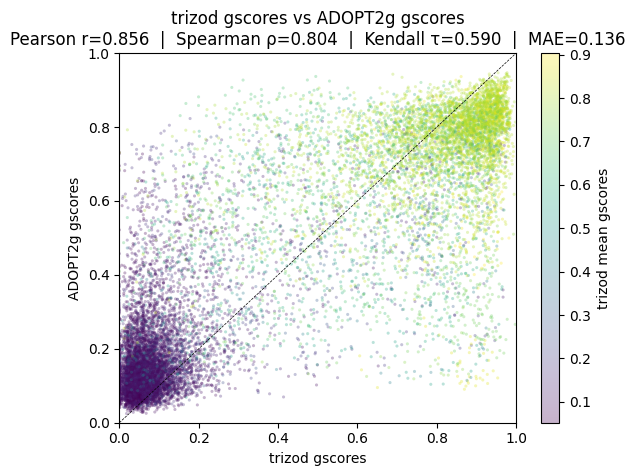

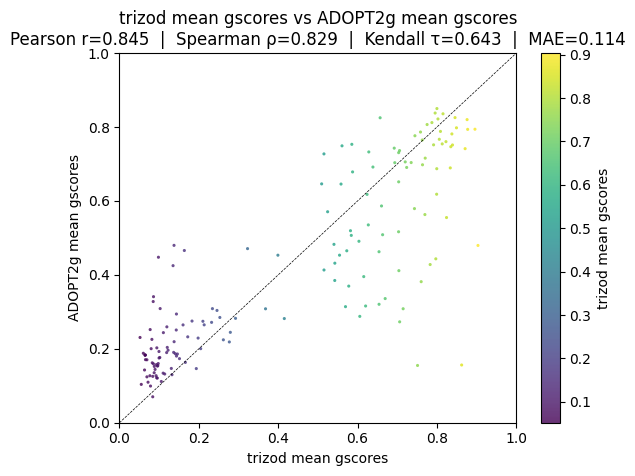

In [59]:
## old adopt models
all_mean_trizod_gscores = np.repeat(df_test["gscores"].apply(np.nanmean).values, df_test["gscores"].apply(len).values)
all_trizod_gscores = np.concatenate(df_test["gscores"].values)


def plot_correlations(scores: list[np.ndarray], labels: list[str]) -> None:
    mask = np.isfinite(scores[0]) & np.isfinite(scores[1])
    pearson_r, _ = pearsonr(scores[0][mask], scores[1][mask])
    spearman_rho, _ = spearmanr(scores[0][mask], scores[1][mask])
    kendall_tau, _ = kendalltau(scores[0][mask], scores[1][mask])
    mae = np.mean(np.abs(scores[0][mask] - scores[1][mask]))
    plt.scatter(scores[0], scores[1], alpha=0.3 if mask.sum() > 1000 else 0.8, s=5, lw=0, c=scores[-1])
    plt.xlabel(labels[0])
    plt.ylabel(labels[1])
    plt.title(
        f"{labels[0]} vs {labels[1]}\nPearson r={pearson_r:.3f}  |  Spearman ρ={spearman_rho:.3f}  |  Kendall τ={kendall_tau:.3f}  |  MAE={mae:.3f}",
    )
    plt.colorbar(label=labels[-1])
    if "gscores" in labels[0]:
        plt.xlim(0, 1)
    if "gscores" in labels[1]:
        plt.ylim(0, 1)
    if ("gscores" in labels[0] and "gscores" in labels[1]) or ("zscores" in labels[0] and "zscores" in labels[1]):
        plt.axline((0.5, 0.5), slope=1, color="k", ls="--", lw=0.5)
    plt.show()


adopt2_gscores = np.concatenate(df_inferred["gscores"].values)
plot_correlations(
    [all_trizod_gscores, adopt2_gscores, all_mean_trizod_gscores],
    ["trizod gscores", "ADOPT2g gscores", "trizod mean gscores"],
)
plot_correlations(
    [df_test["mean_gscore"], df_inferred["mean_gscore"], df_test["mean_gscore"]],
    ["trizod mean gscores", "ADOPT2g mean gscores", "trizod mean gscores"],
)

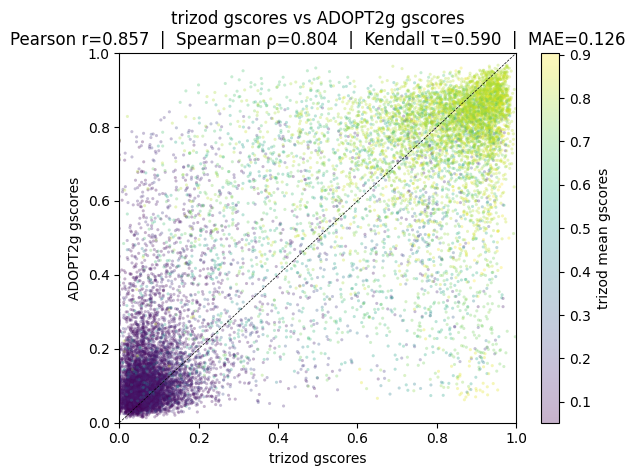

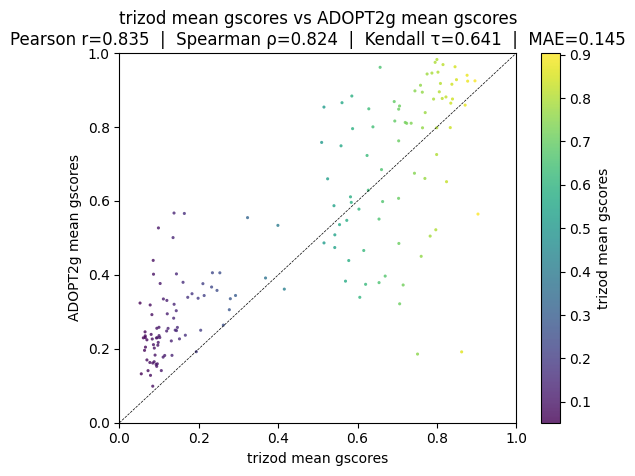

In [60]:
from scipy.special import logit, expit

T = 0.85
plot_correlations(
    [all_trizod_gscores, expit(logit(adopt2_gscores) / T), all_mean_trizod_gscores],
    ["trizod gscores", "ADOPT2g gscores", "trizod mean gscores"],
)
plot_correlations(
    [
        df_test["mean_gscore"],
        np.array([expit(logit(np.nanmean(df_inferred.loc[i, "gscores"]) / T)) for i in df_test.index]),
        df_test["mean_gscore"],
    ],
    ["trizod mean gscores", "ADOPT2g mean gscores", "trizod mean gscores"],
)

ADOPT2g old model, same train-test set


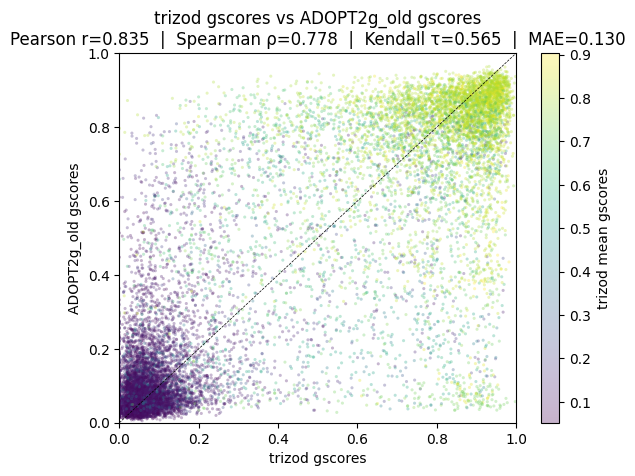

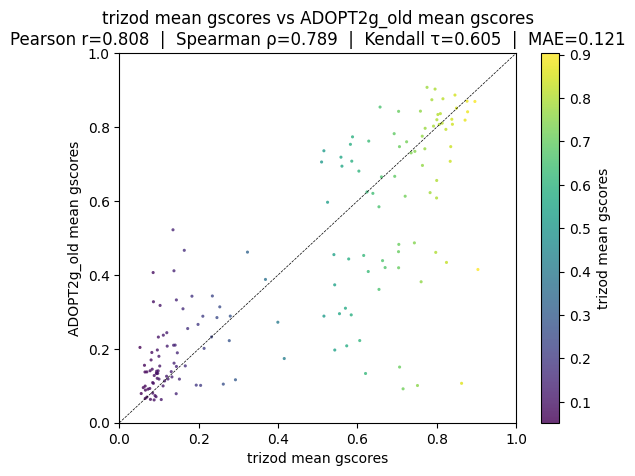

In [61]:
filename = "test-adopt2g_old.csv"
print("ADOPT2g old model, same train-test set")

df_inferred_old = pd.read_csv(
    filename,
    index_col="label",
    converters={
        "gscores_adopt2": lambda x: np.array(json.loads(x), dtype=float),
    },
)
assert df_inferred_old.index.equals(df_inferred.index)

adopt2_gscores = np.concatenate(df_inferred_old["gscores_adopt2"].values)
plot_correlations(
    [all_trizod_gscores, adopt2_gscores, all_mean_trizod_gscores],
    ["trizod gscores", "ADOPT2g_old gscores", "trizod mean gscores"],
)

plot_correlations(
    [df_test["mean_gscore"], df_inferred_old["mean_gscore_adopt2"], df_test["mean_gscore"]],
    ["trizod mean gscores", "ADOPT2g_old mean gscores", "trizod mean gscores"],
)

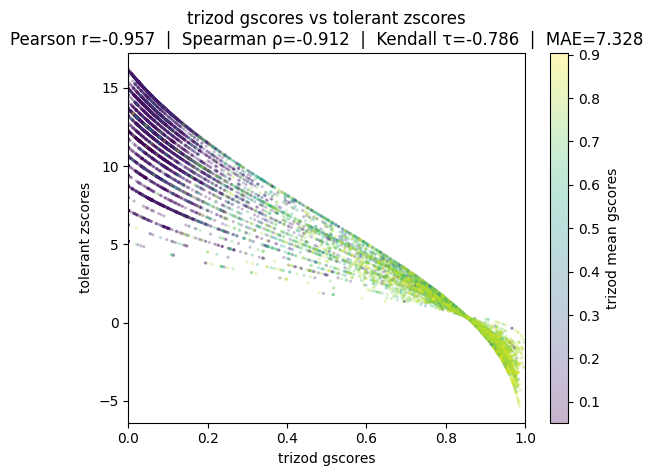

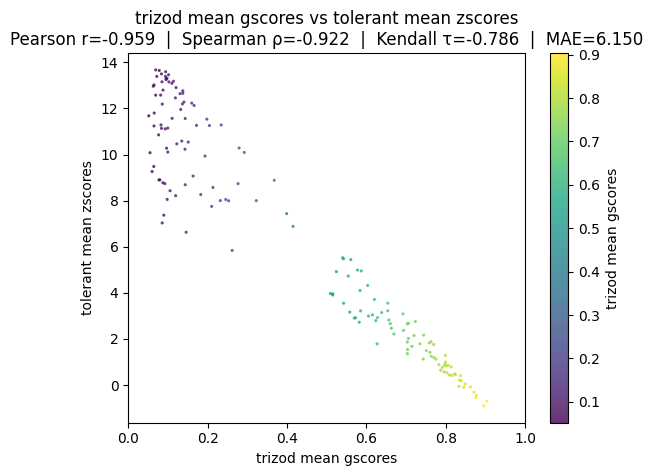

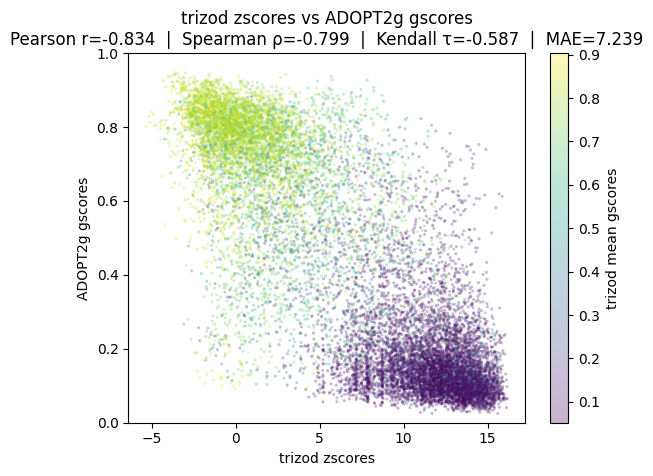

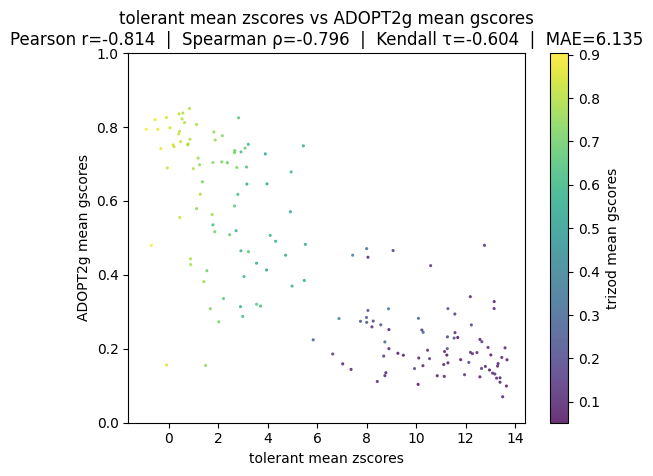

In [62]:
test_zscores = {}
test_mean_zscores = {}
with open("../datasets/trizod-2025_12_12/tolerant.json") as f:
    for line in f:
        data = json.loads(line)
        if data["ID"] in df_test.index:
            test_zscores[data["ID"]] = np.asarray(data["zscores"], dtype=float)
            test_mean_zscores[data["ID"]] = np.nanmean(test_zscores[data["ID"]])
all_test_zscores = np.concatenate([test_zscores[i] for i in df_test.index])
test_mean_zscores = np.array([test_mean_zscores[i] for i in df_test.index])

plot_correlations(
    [all_trizod_gscores, all_test_zscores, all_mean_trizod_gscores],
    ["trizod gscores", "tolerant zscores", "trizod mean gscores"],
)
plot_correlations(
    [df_test["mean_gscore"], test_mean_zscores, df_test["mean_gscore"]],
    ["trizod mean gscores", "tolerant mean zscores", "trizod mean gscores"],
)
plot_correlations(
    [all_test_zscores, np.concatenate(df_inferred["gscores"].values), all_mean_trizod_gscores],
    ["trizod zscores", "ADOPT2g gscores", "trizod mean gscores"],
)
plot_correlations(
    [test_mean_zscores, df_inferred["mean_gscore"], df_test["mean_gscore"]],
    ["tolerant mean zscores", "ADOPT2g mean gscores", "trizod mean gscores"],
)

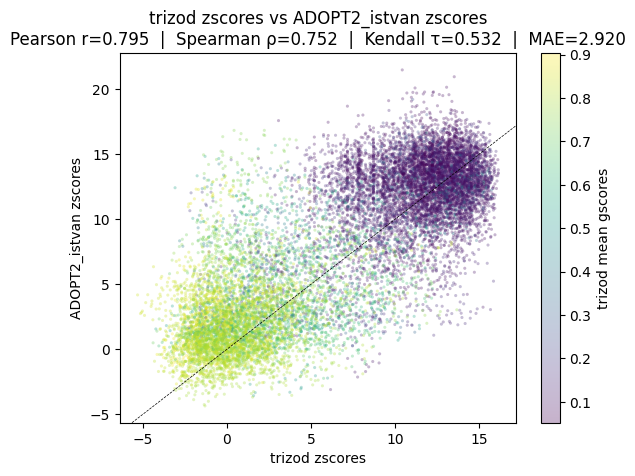

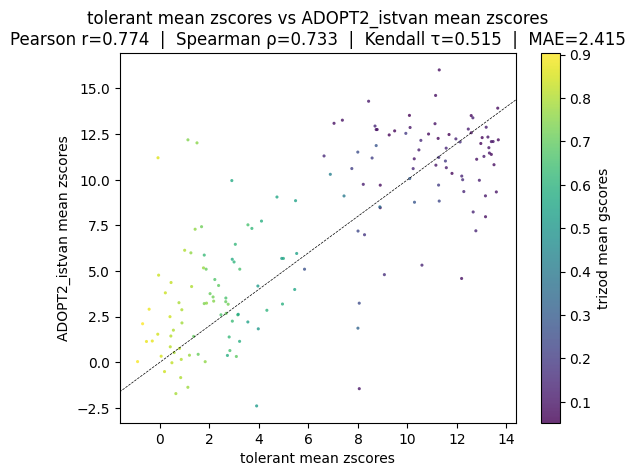

In [63]:
df_istvan_adopt2 = pd.read_csv(
    "test-adopt2_istvan.csv",
    index_col="label",
    converters={"zscores": lambda x: np.array(json.loads(x), dtype=float)},
)
plot_correlations(
    [all_test_zscores, np.concatenate(df_istvan_adopt2["zscores"].values), all_mean_trizod_gscores],
    ["trizod zscores", "ADOPT2_istvan zscores", "trizod mean gscores"],
)
plot_correlations(
    [
        test_mean_zscores,
        np.array([np.nanmean(df_istvan_adopt2.loc[i, "zscores"]) for i in df_test.index]),
        df_test["mean_gscore"],
    ],
    ["tolerant mean zscores", "ADOPT2_istvan mean zscores", "trizod mean gscores"],
)

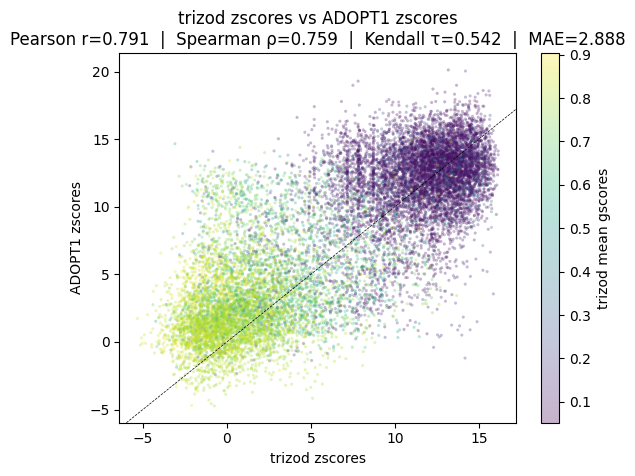

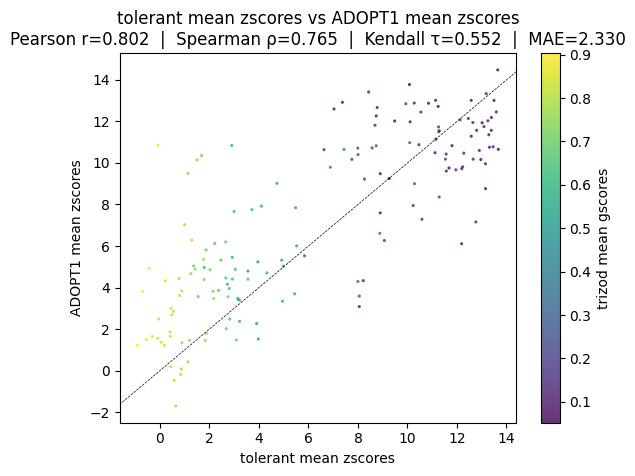

In [64]:
if not os.path.exists("test-adopt1.csv"):
    import requests

    url = "https://adopt.peptone.io/adopt/api/v1/models/lasso_esm-1b_cleared_residue/z_score"

    adopt1_zscores = {}
    for label, row in df_test.iterrows():
        response = requests.post(url, json={"label": label, "sequence": row["sequence"].replace("X", "A")})
        adopt1_zscores[label] = np.asarray(response.json()["z_scores"], dtype=float)
    with open("test-adopt1.csv", "w") as f:
        f.write("label,sequence,mean_zscore,zscores\n")
        for label, row in df_test.iterrows():
            f.write(
                f'{label},{row["sequence"].replace("X", "A")},{np.nanmean(adopt1_zscores[label])},"{json.dumps(adopt1_zscores[label].tolist())}"\n',
            )

df_adopt1 = pd.read_csv(
    "test-adopt1.csv",
    index_col="label",
    converters={"zscores": lambda x: np.array(json.loads(x), dtype=float)},
)

plot_correlations(
    [all_test_zscores, np.concatenate(df_adopt1["zscores"].values), all_mean_trizod_gscores],
    ["trizod zscores", "ADOPT1 zscores", "trizod mean gscores"],
)
plot_correlations(
    [
        test_mean_zscores,
        np.array([np.nanmean(df_adopt1.loc[i, "zscores"]) for i in df_test.index]),
        df_test["mean_gscore"],
    ],
    ["tolerant mean zscores", "ADOPT1 mean zscores", "trizod mean gscores"],
)

2026-01-16 11:18:40 [INFO] adopt2g.scripts.catboost_baseline: Loaded model from /home/michele/workdir/ADOPT2g/models/catboost/catboost_esm.cbm
2026-01-16 11:18:40 [INFO] adopt2g.scripts.catboost_baseline: Loading ESM model to cuda...
2026-01-16 11:18:48 [WARNING] adopt2g.embeddings: Flash Attention 2 not available (libcudart.so.12: cannot open shared object file: No such file or directory), falling back to sdpa attention
Some weights of EsmModel were not initialized from the model checkpoint at facebook/esm2_t33_650M_UR50D and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
/home/michele/miniforge3/envs/adopt2g/lib/python3.12/site-packages/torch/cuda/__init__.py:283: UserWarning: 
    Found GPU0 NVIDIA GB10 which is of cuda capability 12.1.
    Minimum and Maximum cuda capability supported by this version of PyTorch is
    (8.0) - (12.0)
    
  warnings.war

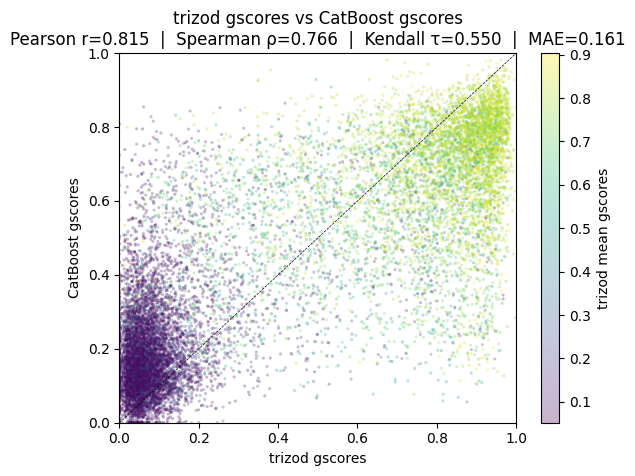

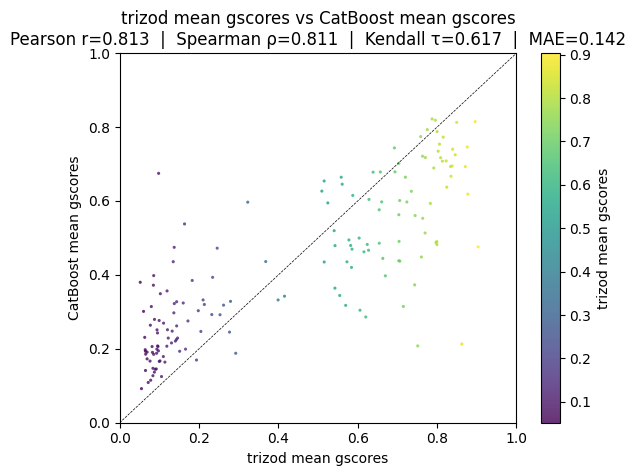

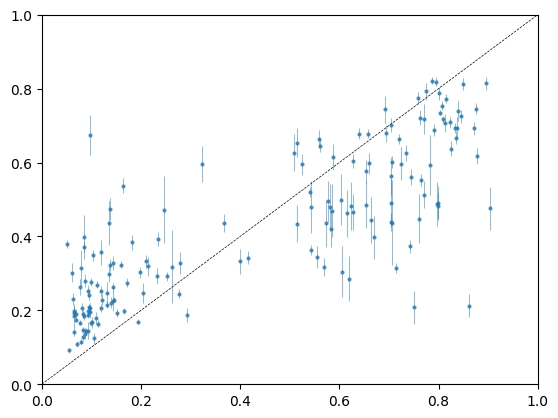

In [65]:
!adopt2g-catboost predict --input test.csv --output test-catboost.csv
df_catboost = pd.read_csv(
    "test-catboost.csv",
    index_col="label",
    # converters={"gscores": lambda x: np.clip(np.array(json.loads(x), dtype=float), 0, 1)},
    converters={
        "gscores": lambda x: np.array(json.loads(x), dtype=float),
        "gscores_lower": lambda x: np.array(json.loads(x), dtype=float),
        "gscores_upper": lambda x: np.array(json.loads(x), dtype=float),
    },
)
assert df_catboost.index.equals(df_inferred.index)

adopt2g_catboost_gscores = np.concatenate(df_catboost["gscores"].values)
print(np.nanmin(adopt2g_catboost_gscores), np.nanmax(adopt2g_catboost_gscores))
plot_correlations(
    [all_trizod_gscores, adopt2g_catboost_gscores, all_mean_trizod_gscores],
    ["trizod gscores", "CatBoost gscores", "trizod mean gscores"],
)

plot_correlations(
    [df_test["mean_gscore"], df_catboost["mean_gscore"], df_test["mean_gscore"]],
    ["trizod mean gscores", "CatBoost mean gscores", "trizod mean gscores"],
)
plt.errorbar(
    df_test["mean_gscore"],
    df_catboost["mean_gscore"],
    yerr=[
        df_catboost["mean_gscore"] - df_catboost["mean_gscore_lower"],
        df_catboost["mean_gscore_upper"] - df_catboost["mean_gscore"],
    ],
    fmt="o",
    markersize=2,
    elinewidth=0.5,
    alpha=0.7,
    capsize=0,
)
plt.axline((0.5, 0.5), slope=1, color="k", ls="--", lw=0.5)
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.show()
